<small>Dataset: heart_v2.csv</small>

# Q16. Disease Decision Tree

Train a decision tree and explain its predictions using a plotted tree.


## Question from Classroom

Disease Classification Using Decision Tree 
Problem statement: Develop a Decision Tree classifier using a suitable labeled public 
medical dataset. 
Tasks to be performed: 
1. Load the dataset and identify the diagnostic target. 
2. Inspect missing values, feature distributions and class imbalance. 
3. Split the dataset into training and testing sets. 
4. Train a Decision Tree classifier. 
5. Predict the classes of unseen test records. 
6. Display accuracy, precision, recall, F1-score and the confusion matrix.


## Understand before coding

Read and inspect -> choose X/y -> stratified split -> training-only imputation -> train a depth-limited tree -> print classification metrics and visualize.


Run the code cells from top to bottom with **Shift + Enter**. If an import is missing, run the following installation line once in a new cell, then restart the kernel. The line below is a comment until you remove `#`.


**Optional package setup (run once in a new Jupyter cell if needed):**

```python
%pip install pandas numpy matplotlib scikit-learn openpyxl
```


**Code layout:** 6 listed tasks → 6 code blocks. Run them in order. Imports and helper definitions are included in the relevant task. Where the PDF repeats a task number, these blocks follow its listed order. Learned preprocessing is fitted only after splitting.


## Task 1. Load the dataset and identify the diagnostic target.

This block implements the task above. Variables from earlier blocks are reused.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
from sklearn.tree import DecisionTreeClassifier,plot_tree
df=pd.read_csv("data/heart_v2.csv").dropna(subset=["heart disease"])
X=df.drop(columns="heart disease")
y=df["heart disease"]
print("Target: heart disease")


Target: heart disease


## Task 2. Inspect missing values, feature distributions and class imbalance.

This block implements the task above. Variables from earlier blocks are reused.


Shape: (270, 5)
   age  sex   BP  cholestrol  heart disease
0   70    1  130         322              1
1   67    0  115         564              0
2   57    1  124         261              1
3   64    1  128         263              0
4   74    0  120         269              0
<class 'pandas.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   age            270 non-null    int64
 1   sex            270 non-null    int64
 2   BP             270 non-null    int64
 3   cholestrol     270 non-null    int64
 4   heart disease  270 non-null    int64
dtypes: int64(5)
memory usage: 10.7 KB
Missing values:
 age              0
sex              0
BP               0
cholestrol       0
heart disease    0
dtype: int64
Summary:
                count        mean        std    min    25%    50%    75%    max
age            270.0   54.433333   9.109067   29.0   48.0   55.0   61.0   77.0
s

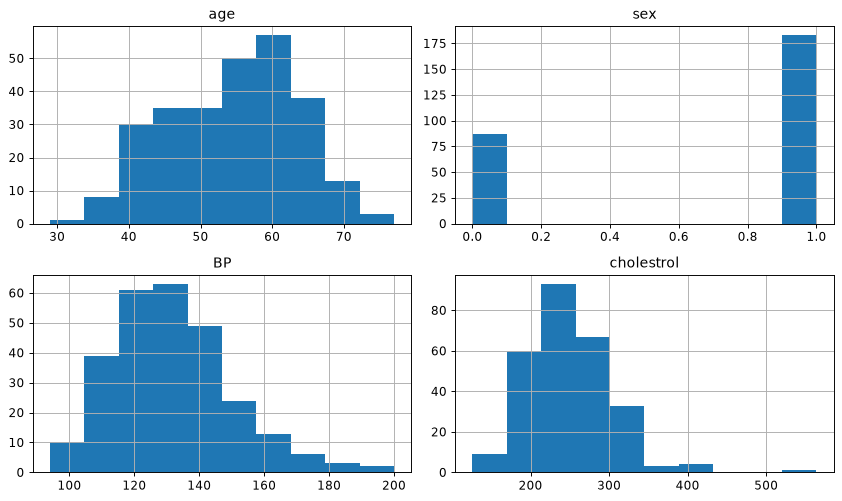

In [2]:
print("Shape:",df.shape)
print(df.head())
df.info()
print("Missing values:\n",df.isna().sum())
print("Summary:\n",df.describe(include="all").T)
print("Class counts:",y.value_counts().to_dict())
X.hist(figsize=(10,6));plt.tight_layout();plt.show()


## Task 3. Split the dataset into training and testing sets.

This block implements the task above. Variables from earlier blocks are reused.


In [3]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
medians=X_train.median()
X_train=X_train.fillna(medians)
X_test=X_test.fillna(medians)


## Task 4. Train a Decision Tree classifier.

This block implements the task above. Variables from earlier blocks are reused.


In [4]:
model=DecisionTreeClassifier(criterion="gini",max_depth=4,random_state=42)
model.fit(X_train,y_train)


## Task 5. Predict the classes of unseen test records.

This block implements the task above. Variables from earlier blocks are reused.


In [5]:
prediction=model.predict(X_test)
print("Predicted classes:",prediction[:10])


Predicted classes: [0 0 1 1 1 0 1 1 1 0]


## Task 6. Display accuracy, precision, recall, F1-score and the confusion matrix.

This block implements the task above. Variables from earlier blocks are reused.


In [6]:
print("Accuracy:",round(accuracy_score(y_test,prediction),4))
print("Class order:",model.classes_)
print("Confusion matrix:\n",confusion_matrix(y_test,prediction,labels=model.classes_))
print(classification_report(y_test,prediction,zero_division=0))


Accuracy: 0.6481
Class order: [0 1]
Confusion matrix:
 [[18 12]
 [ 7 17]]
              precision    recall  f1-score   support

           0       0.72      0.60      0.65        30
           1       0.59      0.71      0.64        24

    accuracy                           0.65        54
   macro avg       0.65      0.65      0.65        54
weighted avg       0.66      0.65      0.65        54



## Viva preparation guide



**1. What are X and y?**

X contains the predictor columns; y contains the target we want to predict. X is a 2D table and y is a 1D series.

**2. Why split training and testing data?**

Fit using the training examples. Evaluate on separate examples to estimate how well the model generalizes.

**3. What do fit() and predict() mean?**

fit() learns parameters from training examples. predict() applies the learned model to new feature rows.

**4. Why random_state=42?**

It makes random splits or model choices reproducible. The number 42 has no special mathematical meaning.

**5. What is data leakage?**

Information unavailable for a real prediction accidentally influences training. Examples: including the answer in X or fitting a scaler on test data. Fit learned preprocessing only on training data.

**6. What is overfitting?**

The model learns training-specific details/noise and does worse on unseen data. Control complexity and use validation or cross-validation.

**7. What is a hyperparameter?**

A setting chosen outside model fitting, such as max_depth, K or the number of trees. Choose it using training validation, not by repeatedly optimizing the final test result.

**8. How do I fix FileNotFoundError or KeyError?**

Open Jupyter in the praceice folder, keep data/ beside this notebook, and print df.columns.tolist() to check exact column names. Do not change X and y row counts separately.

**9. What does the confusion matrix contain?**

Rows are actual classes and columns are predicted classes, in the printed label order. For binary labels [0,1], it is [[TN,FP],[FN,TP]].

**10. Define accuracy, precision, recall and F1.**

Accuracy=(TP+TN)/N. Precision=TP/(TP+FP). Recall=TP/(TP+FN). F1=2PR/(P+R). classification_report prints per-class values and macro/weighted averages. zero_division=0 handles an undefined score.

**11. Why can accuracy be misleading?**

If most examples belong to one class, always predicting that class may give high accuracy. Inspect minority-class recall, precision, F1 and the confusion matrix.

**12. Why stratify=y?**

It approximately preserves class proportions in training and test splits. Each class needs enough examples.

**13. How does a decision tree work?**

It asks feature-threshold questions, sending records down branches until a leaf predicts a class.

**14. Gini impurity?**

Gini=1-sum(p_i^2). It is zero for a pure node. A split is chosen to reduce weighted child impurity.

**15. Entropy?**

Entropy=-sum(p_i*log2(p_i)), with zero-probability terms treated as zero. Information gain is parent entropy minus weighted child entropy.

**16. Why limit max_depth?**

Very deep trees can memorize noise. Limiting depth often reduces overfitting and makes the plotted tree easier to explain.

**17. Does a tree need scaling?**

Usually no. It compares thresholds; it does not calculate Euclidean distances.

**18. What are leaves and feature importance?**

Leaves hold final class decisions. Impurity-based feature importance measures accumulated split improvements; it is not causation and can be biased.

**19. Complexity?**

For a reasonably balanced tree, training is often roughly O(p*n*log n), depending on implementation; prediction follows one path of length equal to tree depth. Deep worst cases can cost more.

**20. What columns are in this actual dataset?**

age, sex, BP, cholestrol and heart disease. The unusual spelling cholestrol is preserved because column names must match the file.

**21. What is the learning objective?**

Predict the dataset label heart disease from the other four attributes. This is a classroom classification exercise, not a validated diagnostic system.


### Task-to-code map

- **Block 1:** Load the dataset and identify the diagnostic target.
- **Block 2:** Inspect missing values, feature distributions and class imbalance.
- **Block 3:** Split the dataset into training and testing sets.
- **Block 4:** Train a Decision Tree classifier.
- **Block 5:** Predict the classes of unseen test records.
- **Block 6:** Display accuracy, precision, recall, F1-score and the confusion matrix.
